In [16]:
import json
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

with open('data/api_troll_farm.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

retweets, meta = [], []
for u in data:
    origen = u['account_id'].upper()
    m = u.get('metadata') or {}
    meta.append({'id': origen, 'card': m.get('payment_hash')})

    for rt in (u.get('activity') or {}).get('retweets') or []:
        destino = rt.upper()
        if origen != destino:
            retweets.append({'Origen': origen, 'Destino': destino, 'Relacion': 'Retweet'})

df_rt = pd.DataFrame(retweets)
df_meta = pd.DataFrame(meta).dropna().drop_duplicates('id')

df_card = df_meta.merge(df_meta, on='card').query('id_x < id_y')[['id_x', 'id_y']]
df_card.columns = ['Origen', 'Destino']
df_card['Relacion'] = 'Misma_Tarjeta'

df_maestra = pd.concat([df_rt, df_card], ignore_index=True)
df_maestra

,Origen,Destino,Relacion
0,TROLL_BOT_1,REAL_USER_11,Retweet
1,REAL_USER_14,REAL_USER_15,Retweet
2,REAL_USER_14,REAL_USER_11,Retweet
3,REAL_USER_13,REAL_USER_3,Retweet
4,REAL_USER_13,REAL_USER_9,Retweet
5,TROLL_BOT_5,REAL_USER_12,Retweet
6,TROLL_BOT_5,TROLL_BOT_1,Retweet
7,REAL_USER_12,REAL_USER_15,Retweet
8,REAL_USER_11,REAL_USER_14,Retweet
9,REAL_USER_11,REAL_USER_6,Retweet


In [17]:
MG = nx.from_pandas_edgelist(
    df_maestra, source='Origen', target='Destino',
    edge_attr='Relacion', create_using=nx.MultiDiGraph()
)

MG.add_nodes_from(u['account_id'].upper() for u in data)

print("Nodos:", MG.number_of_nodes(), "| Aristas:", MG.number_of_edges())

Nodos: 22 | Aristas: 52


In [18]:
aristas_tarjeta = [(u, v) for u, v, d in MG.edges(data=True) if d['Relacion'] == 'Misma_Tarjeta']

G_tarjeta = nx.Graph(aristas_tarjeta)
print("Anillo de bots:", list(nx.connected_components(G_tarjeta)))

Anillo de bots: [{'TROLL_BOT_3', 'TROLL_BOT_2', 'TROLL_BOT_1', 'TROLL_BOT_6', 'TROLL_BOT_4', 'TROLL_BOT_5'}]


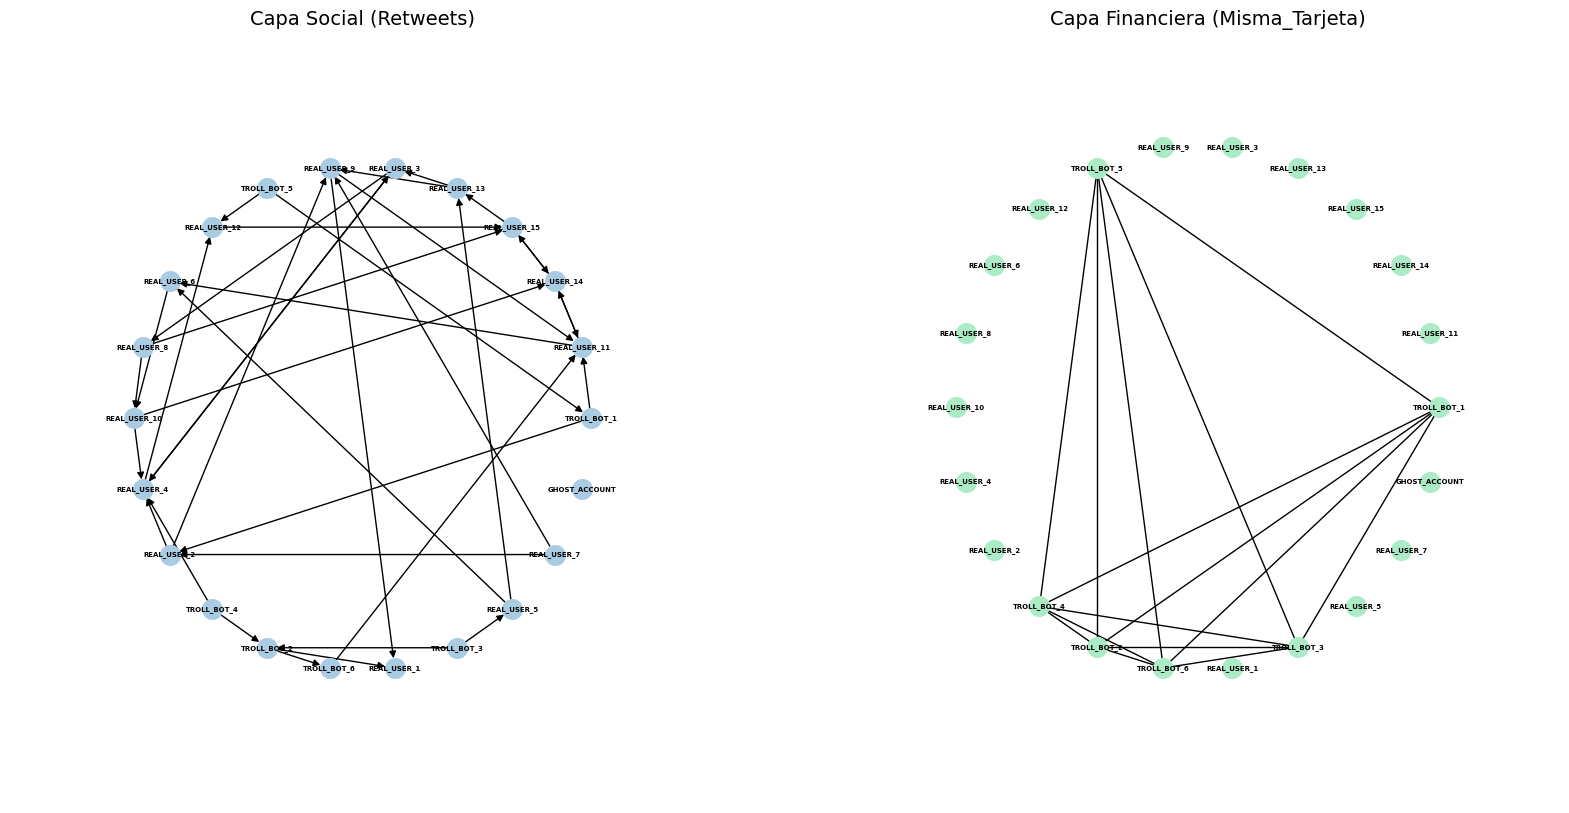

In [25]:
aristas_social = [(u, v) for u, v, d in MG.edges(data=True) if d['Relacion'] == 'Retweet']
G_social = nx.DiGraph()
G_social.add_nodes_from(MG.nodes())
G_social.add_edges_from(aristas_social)

G_tarjeta_full = nx.Graph()
G_tarjeta_full.add_nodes_from(MG.nodes())
G_tarjeta_full.add_edges_from(aristas_tarjeta)

pos_fija = nx.circular_layout(MG)

plt.figure(figsize=(20, 10))

plt.subplot(1, 2, 1)
nx.draw(G_social, pos_fija, with_labels=True, node_color='#A9CCE3', node_size=200, font_weight='bold', font_size=5)
plt.title('Capa Social (Retweets)', fontsize=14)
plt.margins(0.2)

plt.subplot(1, 2, 2)
nx.draw(G_tarjeta_full, pos_fija, with_labels=True, node_color='#ABEBC6', node_size=200, font_weight='bold', font_size=5)
plt.title('Capa Financiera (Misma_Tarjeta)', fontsize=14)
plt.margins(0.2)

plt.show()

# 1. ¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?
TROLL_BOT_1, TROLL_BOT_2, TROLL_BOT_3, TROLL_BOT_4, TROLL_BOT_5, TROLL_BOT_6

# 2. ¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?
VISA-4455-XXXX-9090

# 3. Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?
Como un modelo tabular no puede leer grafos de manera directa, las conexiones se tienen que convertir en columnas numericas. por ejemplo el grado de la tarjeta, o la cantidad de veces que la tarjeta se encuentra compartida entre cuentas.